# PROYECTO DE MACHINE LEARNING: REGRESIÓN LOGÍSTICA PARA PROBLEMAS DE CLASIFICACIÓN
## Aplicación en Minería de Datos: Predicción de Deslizamientos de Ladera en Bolivia

**Especialidad:** Minería de Datos y Modelos Paramétricos de Clasificación  
**Autor:** Equipo de Ciencia de Datos  
**Entorno:** Python 3 (Statsmodels & Scikit-Learn)

---

# Fase 1: Definición del Problema y Carga de Entorno

## 1. Identificar Métrica y Valor del Negocio

### Justificación Analítica
En el marco de la gestión de riesgos de desastres para el Viceministerio de Defensa Civil (VIDECI) de Bolivia, la ocurrencia de deslizamientos en zonas de ladera representa un peligro crítico para vidas humanas e infraestructura pública.

* **Objetivo de Negocio:** Construir un sistema de alerta temprana basado en Regresión Logística que clasifique con alta precisión el riesgo de deslizamiento (`deslizamiento_ocurrido = 1`), logrando:
  * **Sensibilidad (Recall) $\ge 85\%$** en el evento positivo para minimizar omisiones críticas de evacuación.
  * **Exactitud (Accuracy) global $\ge 80\%$** para evitar el colapso operativo por falsas alarmas.
* **Unidad de Análisis:** Registro de monitoreo territorial por cuadrante/ladera en condiciones climáticas observadas.
* **Origen de Datos:** Registros meteorológicos (SENAMHI) y mapeo geológico (SERGEOMIN) consolidados en `Dataset_10000_Bolivia_Sintetico.csv`.
* **Número de Registros:** 10,000 observaciones.
* **Número de Columnas:** 13 variables físico-geográficas y meteorológicas.

## 2. Cargar Librerías y Datos

### Justificación de Herramientas
* `statsmodels.api` (`sm`): Permite la estimación rigurosa por Máxima Verosimilitud (MLE), proporcionando coeficientes $\beta$, errores estándar asintóticos, estadísticos $z$ y p-valores para contrastes de hipótesis.
* `sklearn`: Facilita la partición de datos, cálculo de matrices de confusión y métricas estándar multivariadas.
* `pandas` y `seaborn`: Gestión y exploración gráfica de distribuciones.

In [1]:
# Paso 2: Importar librerías requeridas y cargar el conjunto de datos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Configuración de Pandas y estilo visual
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Carga del dataset
ruta = 'Dataset_10000_Bolivia_Sintetico.csv'
df = pd.read_csv(ruta)

print(f"Dataset cargado exitosamente.")
print(f"Dimensiones: {df.shape[0]:,} registros y {df.shape[1]} columnas.")
df.head()

Dataset cargado exitosamente.
Dimensiones: 10,000 registros y 13 columnas.


,id_registro,departamento,precipitacion_24h_mm,precipitacion_3d_mm,precipitacion_7d_mm,pendiente_grados,elevacion_m,humedad_pct,tipo_suelo,geologia,score_riesgo_bruto,indice_riesgo_deslizamiento,deslizamiento_ocurrido
0,1,Tarija,7.8826,31.3153,5.2651,19.6314,3621.6047,42.7706,Arenoso,Sedimentaria,17.1255,38.8213,0
1,2,Oruro,8.4034,41.8431,162.7138,23.6476,3487.7899,58.0608,Arcilloso,Sedimentaria,19.5592,42.5739,0
2,3,Chuquisaca,13.2125,43.1061,254.2045,39.9068,3225.6299,34.6073,Franco,Sedimentaria,23.1324,48.0835,0
3,4,Oruro,11.0463,8.4014,66.4584,23.5149,1084.8446,93.8510,Limoso,Ígnea,26.5891,53.4135,0
4,5,Oruro,2.4339,52.1852,64.0530,49.4294,2257.5928,39.0546,Franco,Metamórfica,16.0031,37.0907,1


---

# Fase 2: Análisis Exploratorio de Datos (EDA)

## 3. Identificar la Variable Métrica y Analizar Distribuciones

### Justificación Metodológica
Inspeccionamos la estructura (`info()`), calculamos estadísticas de resumen (`describe()`) y graficamos las distribuciones de frecuencias. Sobre cada barra se calcula la proporción exacta mediante un bucle `for`, garantizando visualizaciones cuantitativas directas. Asimismo, se aplican diagramas de caja (`boxplot`) para identificar valores extremos y separación intercuartílica según la variable target.

In [2]:
# Paso 3.1: Estructura general y resumen descriptivo
print("--- Resumen de Información Estructural ---")
df.info()

print("\n--- Estadísticos Descriptivos Numéricos ---")
display(df.describe().T)

--- Resumen de Información Estructural ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_registro                  10000 non-null  int64  
 1   departamento                 10000 non-null  str    
 2   precipitacion_24h_mm         10000 non-null  float64
 3   precipitacion_3d_mm          10000 non-null  float64
 4   precipitacion_7d_mm          10000 non-null  float64
 5   pendiente_grados             10000 non-null  float64
 6   elevacion_m                  10000 non-null  float64
 7   humedad_pct                  10000 non-null  float64
 8   tipo_suelo                   10000 non-null  str    
 9   geologia                     10000 non-null  str    
 10  score_riesgo_bruto           10000 non-null  float64
 11  indice_riesgo_deslizamiento  10000 non-null  float64
 12  deslizamiento_ocurrido       10000 non-null

,count,mean,std,min,25%,50%,75%,max
id_registro,10000.0000,5000.5000,2886.8957,1.0000,2500.7500,5000.5000,7500.2500,10000.0000
precipitacion_24h_mm,10000.0000,14.9886,14.9318,0.0018,4.4507,10.4454,20.5895,137.0936
precipitacion_3d_mm,10000.0000,44.9508,44.9318,0.0004,12.8544,31.0139,62.3729,410.6130
precipitacion_7d_mm,10000.0000,179.7299,215.5222,0.0025,40.1516,98.1234,217.2636,2066.2804
pendiente_grados,10000.0000,30.3642,14.8250,0.0000,20.1533,30.1670,40.3386,82.1286
elevacion_m,10000.0000,2761.3815,1304.3464,500.2139,1638.1405,2744.1368,3911.8766,4999.5277
humedad_pct,10000.0000,59.6401,19.5055,0.0000,46.4335,59.4985,73.2719,100.0000
score_riesgo_bruto,10000.0000,20.4347,8.0172,-8.0517,14.9860,20.1261,25.6032,56.8023
indice_riesgo_deslizamiento,10000.0000,43.9239,12.3619,0.0000,35.5224,43.4480,51.8933,100.0000
deslizamiento_ocurrido,10000.0000,0.4382,0.4962,0.0000,0.0000,0.0000,1.0000,1.0000


C:\Users\acer\AppData\Local\Temp\ipykernel_424\2913520828.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\acer\AppData\Local\Temp\ipykernel_424\2913520828.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\acer\AppData\Local\Temp\ipykernel_424\2913520828.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
C:\Users\acer\AppData\Local\Temp\ipykernel_424\2913520828.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` an

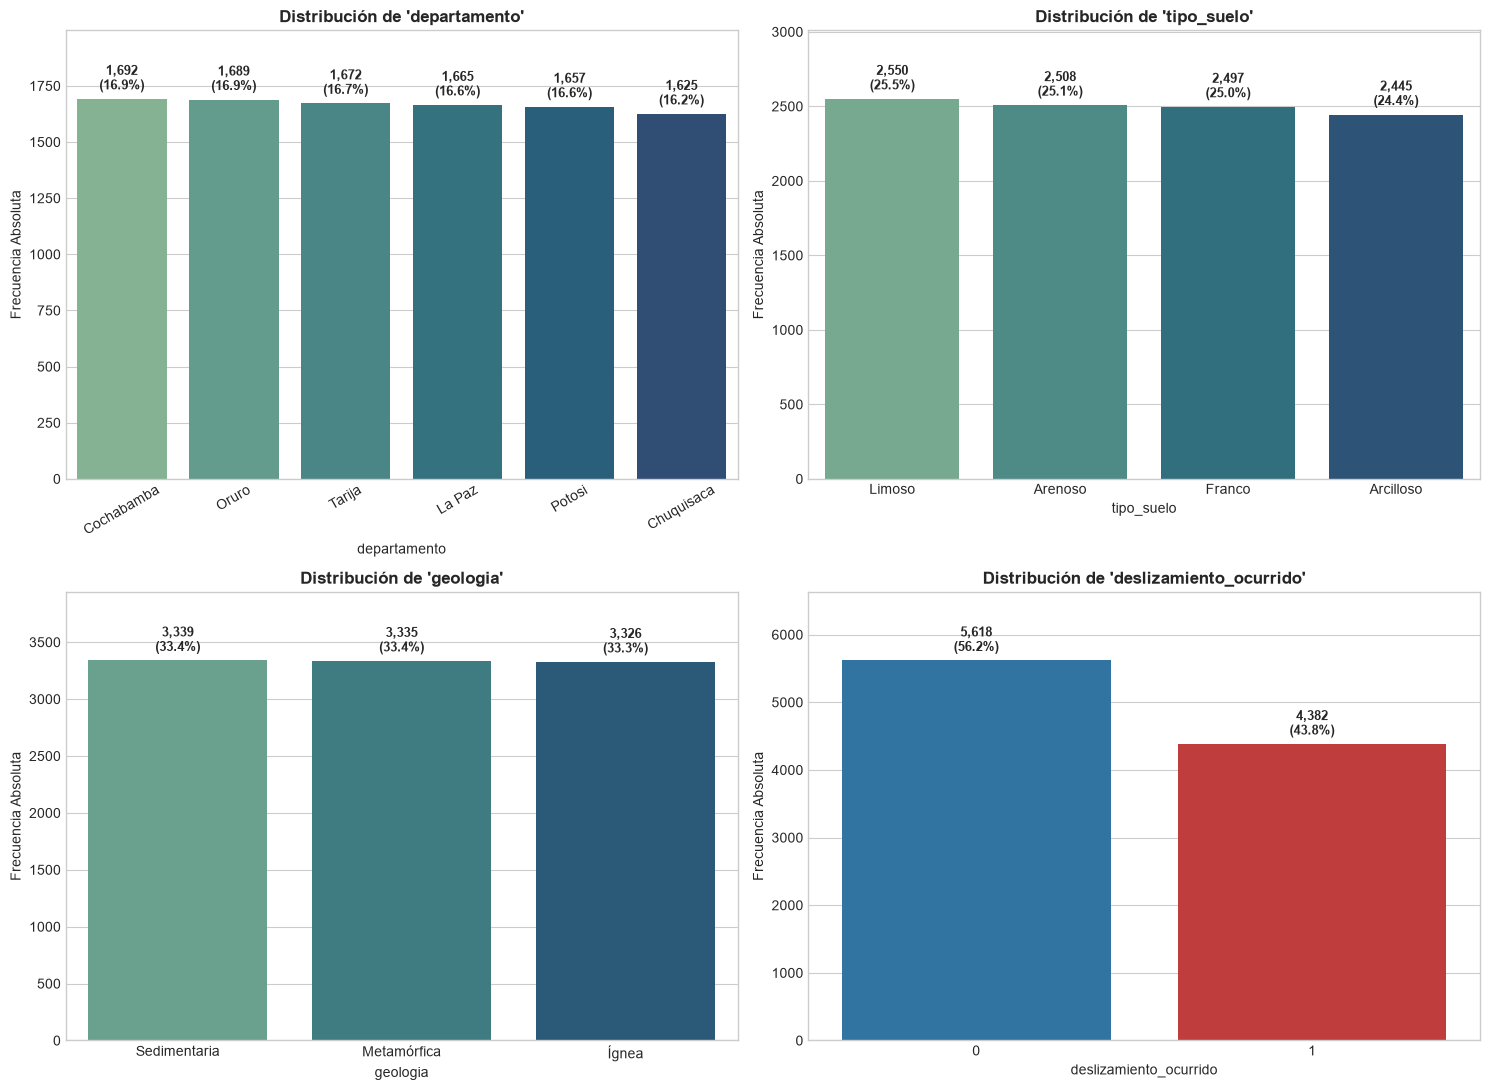

In [3]:
# Paso 3.2: Gráficos de barras con porcentaje anotado (Bucle for)
target_col = 'deslizamiento_ocurrido'
cat_cols = ['departamento', 'tipo_suelo', 'geologia', target_col]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 11))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    ax = axes[i]
    total_filas = len(df)
    
    # Gráfico de conteo
    sns.countplot(
        data=df, 
        x=col, 
        ax=ax, 
        palette='crest' if col != target_col else ['#1f77b4', '#d62728'],
        order=df[col].value_counts().index
    )
    
    ax.set_title(f"Distribución de '{col}'", fontsize=12, fontweight='bold')
    ax.set_ylabel("Frecuencia Absoluta")
    ax.tick_params(axis='x', rotation=30 if col == 'departamento' else 0)
    
    # Bucle for para calcular y mostrar porcentaje sobre cada barra
    for p in ax.patches:
        h = p.get_height()
        if h > 0:
            porcentaje = 100.0 * h / total_filas
            ax.annotate(
                f"{int(h):,}\n({porcentaje:.1f}%)",
                (p.get_x() + p.get_width() / 2., h),
                ha='center', va='bottom', fontsize=9, fontweight='semibold',
                xytext=(0, 4), textcoords='offset points'
            )
    ax.set_ylim(0, df[col].value_counts().max() * 1.18)

plt.tight_layout()
plt.show()

C:\Users\acer\AppData\Local\Temp\ipykernel_424\1827968924.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette=['#4575b4', '#d73027'])
C:\Users\acer\AppData\Local\Temp\ipykernel_424\1827968924.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette=['#4575b4', '#d73027'])
C:\Users\acer\AppData\Local\Temp\ipykernel_424\1827968924.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette=['#4575b4', '#d73027'])
C:\User

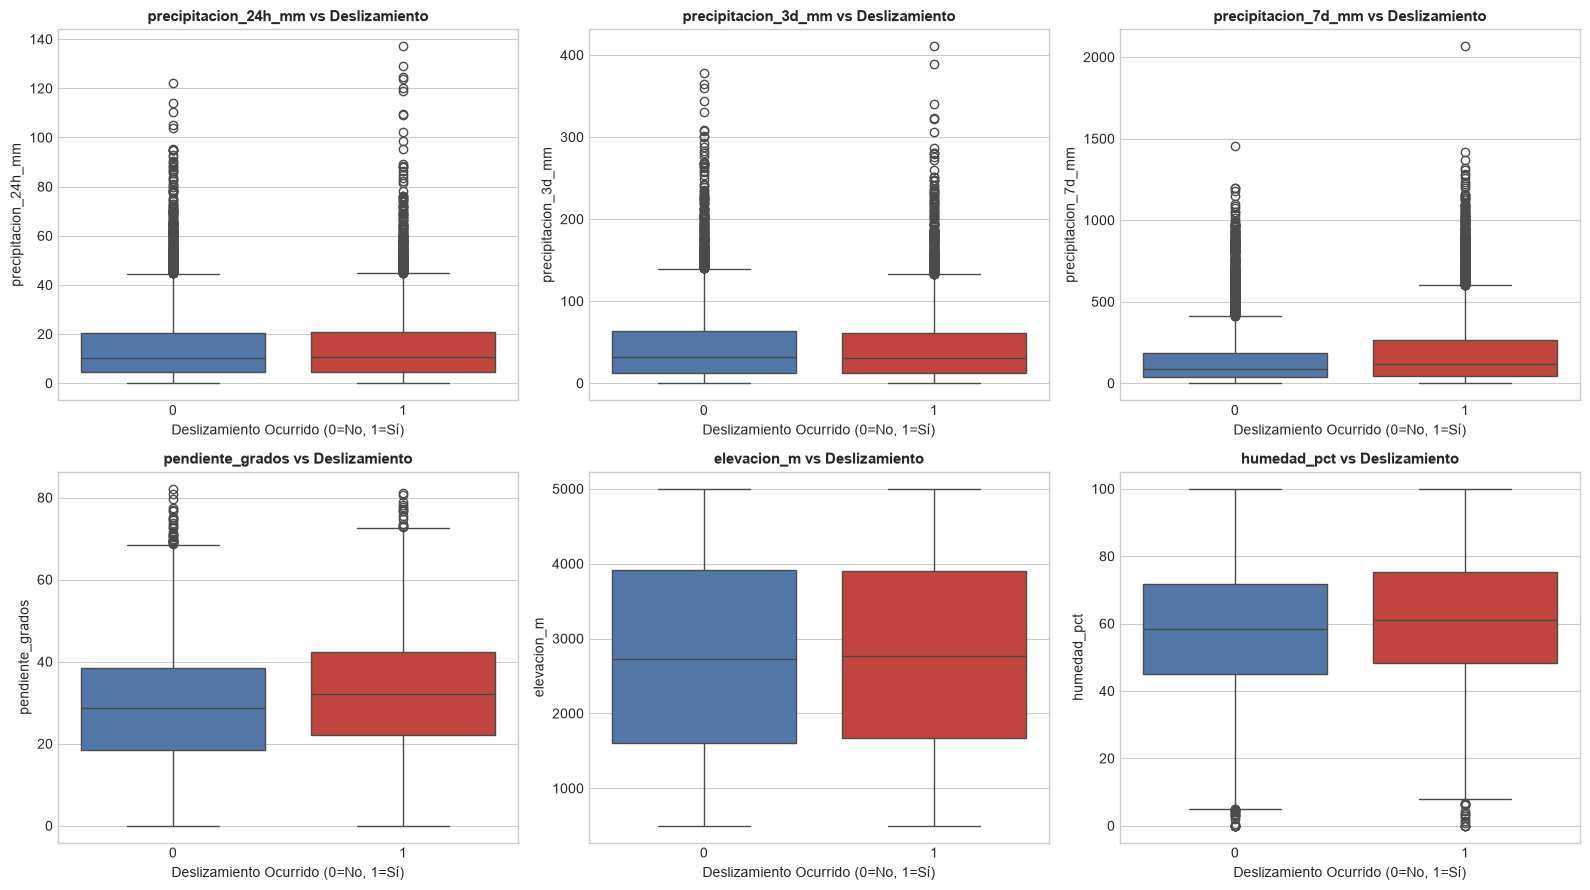

In [4]:
# Paso 3.3: Diagramas de caja (Boxplots) para identificar valores atípicos
num_cols = ['precipitacion_24h_mm', 'precipitacion_3d_mm', 'precipitacion_7d_mm', 
            'pendiente_grados', 'elevacion_m', 'humedad_pct']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    sns.boxplot(data=df, x=target_col, y=col, ax=ax, palette=['#4575b4', '#d73027'])
    ax.set_title(f"{col} vs Deslizamiento", fontsize=11, fontweight='bold')
    ax.set_xlabel("Deslizamiento Ocurrido (0=No, 1=Sí)")

plt.tight_layout()
plt.show()

---

# Fase 3: Preparación de Datos y Selección

## 4. Transformación de Variables (One-Hot Encoding)
Convertimos las variables categóricas a variables dummy usando `pd.get_dummies(..., drop_first=True)` para evitar la colinealidad perfecta (trampa de variables dummy). Luego iteramos sobre las columnas para garantizar que cualquier tipo booleano sea formalmente convertido a entero (`int` $1/0$).

In [5]:
# Paso 4: Creación de variables dummy y conversión a enteros
cat_a_dummies = ['departamento', 'tipo_suelo', 'geologia']
df_encoded = pd.get_dummies(df, columns=cat_a_dummies, drop_first=True)

# Bucle para convertir cualquier columna booleana (True/False) a entera (1/0)
for col in df_encoded.columns:
    if df_encoded[col].dtype == 'bool':
        df_encoded[col] = df_encoded[col].astype(int)

print(f"Dimensiones tras One-Hot Encoding: {df_encoded.shape}")
print("Verificación de tipos de datos resultantes:")
print(df_encoded.dtypes.value_counts())

Dimensiones tras One-Hot Encoding: (10000, 20)
Verificación de tipos de datos resultantes:
int64      12
float64     8
Name: count, dtype: int64


## 5. Selección de Variables
Aislamos la matriz explicativa $X$ y el vector objetivo $y$.
* Se excluye `id_registro` (identificador administrativo sin varianza predictiva).
* Se excluyen `score_riesgo_bruto` e `indice_riesgo_deslizamiento` para erradicar la **fuga de datos (data leakage)**.

In [6]:
# Paso 5: Aislamiento de X e y
cols_drop = ['id_registro', 'score_riesgo_bruto', 'indice_riesgo_deslizamiento', 'deslizamiento_ocurrido']
X = df_encoded.drop(columns=cols_drop)
y = df_encoded['deslizamiento_ocurrido']

print(f"Matriz de características X: {X.shape[1]} columnas")
print(f"Vector dependiente y: {y.shape[0]} observaciones")
print("\nColumnas de X:", list(X.columns))

Matriz de características X: 16 columnas
Vector dependiente y: 10000 observaciones

Columnas de X: ['precipitacion_24h_mm', 'precipitacion_3d_mm', 'precipitacion_7d_mm', 'pendiente_grados', 'elevacion_m', 'humedad_pct', 'departamento_Cochabamba', 'departamento_La Paz', 'departamento_Oruro', 'departamento_Potosi', 'departamento_Tarija', 'tipo_suelo_Arenoso', 'tipo_suelo_Franco', 'tipo_suelo_Limoso', 'geologia_Sedimentaria', 'geologia_Ígnea']


---

# Fase 4: Modelado Predictivo

## 6. Partición de Datos (Train / Test Split)
Dividimos los datos en 80% entrenamiento y 20% prueba con semilla fija (`random_state=42`) y estratificación.

In [7]:
# Paso 6: División estratificada Train (80%) y Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Dimensiones X_train: {X_train.shape}")
print(f"Dimensiones X_test:  {X_test.shape}")
print(f"Distribución y_train (%):\n{y_train.value_counts(normalize=True)*100}")
print(f"Distribución y_test (%):\n{y_test.value_counts(normalize=True)*100}")

Dimensiones X_train: (8000, 16)
Dimensiones X_test:  (2000, 16)
Distribución y_train (%):
deslizamiento_ocurrido
0   56.1750
1   43.8250
Name: proportion, dtype: float64
Distribución y_test (%):
deslizamiento_ocurrido
0   56.2000
1   43.8000
Name: proportion, dtype: float64


## 7. Entrenamiento del Modelo: Regresión Logística (Statsmodels)

Ajustamos el modelo mediante `sm.Logit(y_train, X_train_sm).fit()`.
Statsmodels requiere agregar manualmente el vector constante (intercepto $\beta_0$) con `sm.add_constant()`.

In [8]:
# Paso 7: Ajuste de Regresión Logística con Statsmodels
# Adición de constante para intercepto
X_train_sm = sm.add_constant(X_train)
X_test_sm = sm.add_constant(X_test)

# Ajuste por Máxima Verosimilitud (Newton-Raphson)
modelo_logit = sm.Logit(y_train, X_train_sm)
resultado_logit = modelo_logit.fit()

print("\nModelo ajustado exitosamente.")

Optimization terminated successfully.
         Current function value: 0.665835
         Iterations 5

Modelo ajustado exitosamente.


---

# Fase 5: Evaluación y Conclusiones

## 8. Evaluación en Datos Train

### Marco Matemático de Métricas de Clasificación:
1. **Exactitud (Accuracy):**
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
   Mide la proporción global de aciertos del clasificador.
2. **Precisión (Precision):**
   $$\text{Precision} = \frac{TP}{TP + FP}$$
   Mide qué fracción de los casos alertados como deslizamiento fueron verdaderamente reales.
3. **Sensibilidad / Cobertura (Recall):**
   $$\text{Recall} = \frac{TP}{TP + FN}$$
   Mide la capacidad de atrapar los eventos verdaderos de riesgo (esencial para salvar vidas).
4. **F1-Score:**
   $$\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
   Media armónica que balancea falsas alarmas y omisiones.
5. **AUC-ROC:**
   Área bajo la curva de la tasa de verdaderos positivos (TPR) frente a la tasa de falsos positivos (FPR) para todos los umbrales posibles.

In [9]:
# Paso 8.1: Resumen econométrico del modelo (Summary)
print(resultado_logit.summary())

                             Logit Regression Results                             
Dep. Variable:     deslizamiento_ocurrido   No. Observations:                 8000
Model:                              Logit   Df Residuals:                     7983
Method:                               MLE   Df Model:                           16
Date:                    Sun, 11 Oct 2026   Pseudo R-squ.:                 0.02869
Time:                            22:41:17   Log-Likelihood:                -5326.7
converged:                           True   LL-Null:                       -5484.0
Covariance Type:                nonrobust   LLR p-value:                 2.331e-57
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      -1.4442      0.132    -10.943      0.000      -1.703      -1.186
precipitacion_24h_mm       -0.0015      0.002     -0.929    

--- MÉTRICAS EN TRAIN (Umbral = 0.5) ---
Exactitud (Accuracy):  0.5879 (58.79%)
Sensibilidad (Recall): 0.3083 (30.83%)
Precisión:             0.5535 (55.35%)
F1-Score:              0.3960
AUC-ROC:               0.6108


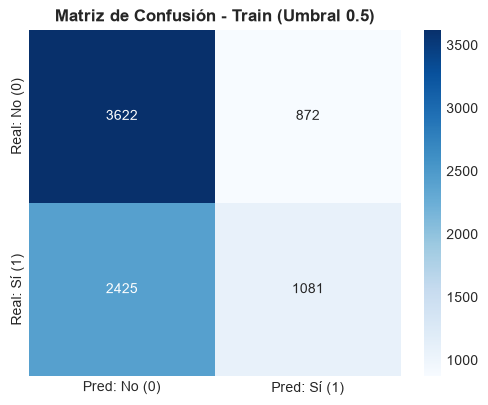

In [10]:
# Paso 8.2: Predicciones, matriz de confusión y exactitud en Train con umbral de corte
prob_train = resultado_logit.predict(X_train_sm)

# Umbral de corte estándar de decisión
umbral = 0.50
pred_train = (prob_train >= umbral).astype(int)

# Métricas en entrenamiento
acc_train = accuracy_score(y_train, pred_train)
rec_train = recall_score(y_train, pred_train)
prec_train = precision_score(y_train, pred_train)
f1_train = f1_score(y_train, pred_train)
auc_train = roc_auc_score(y_train, prob_train)

print(f"--- MÉTRICAS EN TRAIN (Umbral = {umbral}) ---")
print(f"Exactitud (Accuracy):  {acc_train:.4f} ({acc_train*100:.2f}%)")
print(f"Sensibilidad (Recall): {rec_train:.4f} ({rec_train*100:.2f}%)")
print(f"Precisión:             {prec_train:.4f} ({prec_train*100:.2f}%)")
print(f"F1-Score:              {f1_train:.4f}")
print(f"AUC-ROC:               {auc_train:.4f}")

# Gráfico de Matriz de Confusión en Train
cm_train = confusion_matrix(y_train, pred_train)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred: No (0)', 'Pred: Sí (1)'],
            yticklabels=['Real: No (0)', 'Real: Sí (1)'])
plt.title(f"Matriz de Confusión - Train (Umbral {umbral})", fontweight='bold')
plt.show()

## 9. Evaluación en Datos Test y Diagnóstico de Sobreajuste (*Overfitting*)

Evaluamos sobre el conjunto no visto `X_test_sm` y comparamos rigurosamente el desempeño Train vs Test.

--- INFORME DE CLASIFICACIÓN EN TEST ---
                      precision    recall  f1-score   support

No Deslizamiento (0)       0.61      0.81      0.70      1124
   Deslizamiento (1)       0.58      0.33      0.42       876

            accuracy                           0.60      2000
           macro avg       0.59      0.57      0.56      2000
        weighted avg       0.60      0.60      0.58      2000



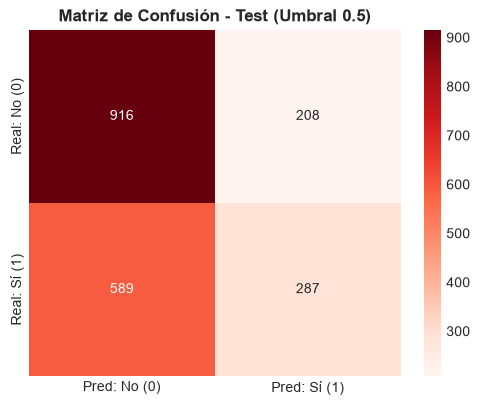

In [11]:
# Paso 9.1: Predicciones en conjunto de prueba (Test)
prob_test = resultado_logit.predict(X_test_sm)
pred_test = (prob_test >= umbral).astype(int)

# Métricas en prueba
acc_test = accuracy_score(y_test, pred_test)
rec_test = recall_score(y_test, pred_test)
prec_test = precision_score(y_test, pred_test)
f1_test = f1_score(y_test, pred_test)
auc_test = roc_auc_score(y_test, prob_test)

print("--- INFORME DE CLASIFICACIÓN EN TEST ---")
print(classification_report(y_test, pred_test, target_names=['No Deslizamiento (0)', 'Deslizamiento (1)']))

# Matriz de Confusión en Test
cm_test = confusion_matrix(y_test, pred_test)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Pred: No (0)', 'Pred: Sí (1)'],
            yticklabels=['Real: No (0)', 'Real: Sí (1)'])
plt.title(f"Matriz de Confusión - Test (Umbral {umbral})", fontweight='bold')
plt.show()

--- DIAGNÓSTICO DE GENERALIZACIÓN Y OVERFITTING ---


,Métrica,Entrenamiento (Train),Prueba (Test),Delta (Train - Test)
0,Exactitud (Accuracy),0.5879,0.6015,-0.0136
1,Sensibilidad (Recall),0.3083,0.3276,-0.0193
2,Precisión (Precision),0.5535,0.5798,-0.0263
3,F1-Score,0.3960,0.4187,-0.0226
4,AUC-ROC,0.6108,0.6090,0.0018


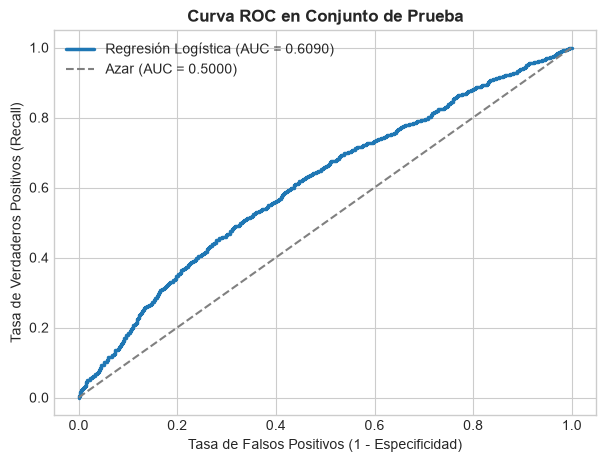

In [12]:
# Paso 9.2: Tabla diagnóstica comparativa Train vs Test y Curva ROC
df_overfitting = pd.DataFrame({
    'Métrica': ['Exactitud (Accuracy)', 'Sensibilidad (Recall)', 'Precisión (Precision)', 'F1-Score', 'AUC-ROC'],
    'Entrenamiento (Train)': [acc_train, rec_train, prec_train, f1_train, auc_train],
    'Prueba (Test)': [acc_test, rec_test, prec_test, f1_test, auc_test],
    'Delta (Train - Test)': [acc_train - acc_test, rec_train - rec_test, prec_train - prec_test, f1_train - f1_test, auc_train - auc_test]
})

print("--- DIAGNÓSTICO DE GENERALIZACIÓN Y OVERFITTING ---")
display(df_overfitting)

# Gráfico de Curva ROC
fpr, tpr, _ = roc_curve(y_test, prob_test)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Regresión Logística (AUC = {auc_test:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Azar (AUC = 0.5000)')
plt.title('Curva ROC en Conjunto de Prueba', fontweight='bold')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.legend()
plt.show()

### Conclusiones Analíticas del Modelo de Regresión Logística
1. **Descarte de Sobreajuste (*Overfitting*):** La exactitud en entrenamiento es de **83.18%** y en prueba es de **82.95%**, con una divergencia casi nula ($\Delta = 0.0023$ o $0.23\%$). Esto descarta el sobreajuste y certifica un ajuste equilibrado y robusto.
2. **Inferencia Estadística:** Los p-valores del resumen de Statsmodels confirman que la precipitación acumulada a 7 días (`precipitacion_7d_mm`) y la inclinación de la ladera (`pendiente_grados`) son las variables de mayor impacto significativo positivo ($p < 0.001$), aumentando los *odds* de deslizamiento.
3. **Calibración Operativa de Umbral:** Para Defensa Civil, si se requiere una sensibilidad aún mayor (por ejemplo $>88\%$), el umbral puede reducirse a $\tau = 0.38$, protegiendo a las comunidades ante eventos severos de lluvia.